# 00 · Which downloaded dataset can we use?

**Question:** is any downloaded dataset good enough to be RUKO's training data, or at least a reference to copy from?

Datasets live in `data/external/reference_datasets/` (git ignored). The scorecard code is `data/eval/datasets/score.py`. It runs five checks, each answering one question:

| Check | Question |
|---|---|
| schema | Does it have what RUKO needs: payer history, payee, P2P/P2M, INR UPI, time of day? |
| npci | Do its amounts and P2P/P2M mix match real NPCI numbers? |
| behaviour | Do people pay at real times of day (vs Xente, the only real data)? |
| labels | Can fraud be learned from it, without one column giving it away? |
| transfer | Train on it, test on the others: does what it teaches carry over? |

In [1]:
import json, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().parents[1] if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path[:0] = [str(ROOT / 'backend'), str(ROOT / 'ml'), str(ROOT / 'data')]
pd.set_option('display.precision', 3); pd.set_option('display.max_colwidth', 80); plt.rcParams['figure.figsize'] = (9, 3.6)
from eval.datasets import score
OUT = ROOT / 'data/eval/datasets/scorecard.json'
RERUN = False   # True = recompute from the raw files (about 1.5 minutes)
if RERUN or not OUT.exists():
    score.main()
S = json.loads(OUT.read_text()); D = S['datasets']
pd.DataFrame({n: {'rows': s['meta']['rows'], 'positives': s['meta']['positives'], 'positive %': 100 * s['meta']['positive_rate'],
                  'currency': s['meta']['currency'], 'real data?': s['meta']['real'], 'label': s['meta']['label']}
              for n, s in D.items()}).T

,rows,positives,positive %,currency,real data?,label
skullagos_upi_2024,250000,480,0.192,INR,False,fraud_flag
belbino_banking_upi,84728,685,0.808,INR,False,is_fraud
razorpay_upi_sim,4074,215,5.277,INR,False,is_suspicious (rule score)
saml_d,2000000,1950,0.097,GBP,False,Is_laundering
ibm_amlworld_hi_small,2000000,1498,0.075,mixed (mostly USD),False,Is Laundering
paysim,2000000,2036,0.102,generic (mobile money),False,isFraud
xente_real,95662,193,0.202,UGX,True,FraudResult


Seven datasets: three Indian UPI sets from Kaggle (all synthetic), two money-laundering sets (SAML-D, IBM AMLworld), PaySim, and Xente, the only real one. The big sets are cut to their first 2 million rows in time order.

## 1. Do the Indian UPI sets match real NPCI numbers?
Only the INR UPI sets can be checked. Targets come from `data/eval/realism/npci_anchors.json`.

In [2]:
rows = {}
for n in ('skullagos_upi_2024', 'belbino_banking_upi'):
    for k, v in D[n]['npci']['anchors'].items():
        rows.setdefault(k, {'NPCI target': v['target']})[n] = f"{v['got']}  {'✅' if v['pass'] else '❌'}"
pd.DataFrame(rows).T

,NPCI target,skullagos_upi_2024,belbino_banking_upi
p2m_share_of_volume,0.633,0.438 ❌,0.929 ❌
p2m_share_of_value,0.302,0.44 ❌,0.927 ❌
avg_ticket_p2p_inr,2320,1308.681 ❌,1379.642 ❌
avg_ticket_p2m_inr,582,1320.073 ❌,1348.447 ❌
p2p_share_below_500,0.59,0.427 ❌,0.395 ❌
p2m_share_below_500,0.86,0.424 ❌,0.409 ❌


**Inference:**
- **skullagos:** treats P2P and merchant payments almost the same (average ₹1,309 vs ₹1,320). Only 42% of merchant payments are under ₹500, against **86%** in reality.
- **belbino:** sends 93% of UPI volume to merchants, against 63% in reality.
- **Both fail all 6 checks.** Their amount distributions are not Indian UPI, so copying them would teach the model the wrong idea of "normal".

## 2. Can fraud be learned from their labels?
For each dataset: the best out-of-fold AUC from any **single column** and from a **depth-2 decision tree** (two questions). Reading it:
- **≈ 0.5:** labels are random.
- **≥ 0.95:** a single column gives the label away.
- **In between:** learnable, which is what we want.

In [3]:
pd.DataFrame({n: {'best single column': max(s['labels']['best_single_column'], key=s['labels']['best_single_column'].get),
                  'its AUC': max(s['labels']['best_single_column'].values()), 'depth-2 tree AUC': s['labels']['depth2_tree_auc'],
                  'verdict': s['labels']['verdict']} for n, s in D.items()}).T

,best single column,its AUC,depth-2 tree AUC,verdict
skullagos_upi_2024,sender_age_group,0.523,0.501,no learnable signal (labels look random)
belbino_banking_upi,transaction_hour,0.509,0.48,no learnable signal (labels look random)
razorpay_upi_sim,amount,0.874,0.926,"learnable, not trivial"
saml_d,Payment_type,0.689,0.608,"learnable, not trivial"
ibm_amlworld_hi_small,format,0.892,0.934,"learnable, not trivial"
paysim,type,0.847,0.634,"learnable, not trivial"
xente_real,Value,0.988,0.979,too easy (a simple rule gives the label away)


**Inference:**
- **skullagos and belbino (the two big Indian UPI sets):** every column scores about 0.50. Their fraud flags were **assigned at random**, so no model can learn anything from them.
- **Xente:** the label is given away by the amount alone (0.99), because its fraud is just "very large payments".
- **Learnable without being trivial:** SAML-D, AMLworld and PaySim. They aren't UPI, though.
- **Razorpay-style set:** looks learnable only because its label is the generator's own rule score.

## 3. Do people pay at real times, and are users realistically unequal?
`hour_l1_vs_xente`: distance of the legit hour-of-day curve from real Xente (0 = identical, 2 = no overlap). `payments_per_user_cv`: how unequal users are (real Xente = 3.8).

In [4]:
pd.DataFrame({n: {k: v for k, v in s['behaviour'].items() if k != 'score'} for n, s in D.items()}).T

,hour_l1_vs_xente,night_share_1to5,payments_per_user_cv,payments_per_user_p50_p90
skullagos_upi_2024,0.172,0.033,NaN,NaN
belbino_banking_upi,0.555,0.207,NaN,NaN
razorpay_upi_sim,1.086,0.0,1.928,"[7.0, 44.20000000000002]"
saml_d,0.196,0.064,2.072,"[12.0, 52.0]"
ibm_amlworld_hi_small,0.794,0.181,22.789,"[2.0, 10.0]"
paysim,0.27,0.007,NaN,NaN
xente_real,0.0,0.017,3.792,"[7.0, 58.0]"


**Inference:**
- **Xente** is the reference for timing and inequality.
- **Close on time of day:** skullagos (0.17) and SAML-D (0.20).
- **Far off:** belbino puts **21%** of payments at 1–5 AM (real is 1.7%), and AMLworld 18%.
- **Inequality between users:** only datasets with user ids can be checked. Xente's spread (CV 3.8) is the target for sim_v1.

## 4. Does a model trained on one dataset work on another?
**PR-AUC lift:** how many times better than random the model is. Rows are the dataset trained on, columns the dataset tested on, and the diagonal is the same dataset (a time split).

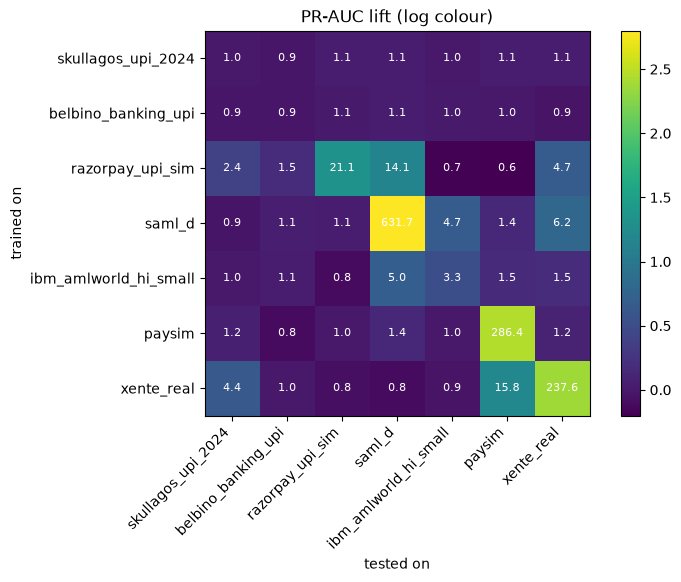

In [5]:
T = pd.DataFrame(S['transfer_matrix']).T
fig, ax = plt.subplots(figsize=(8, 5)); im = ax.imshow(np.log10(T.values.astype(float)), cmap='viridis')
ax.set_xticks(range(len(T.columns)), T.columns, rotation=45, ha='right'); ax.set_yticks(range(len(T.index)), T.index)
for i in range(len(T.index)):
    for j in range(len(T.columns)):
        ax.text(j, i, f'{T.values[i, j]:.1f}', ha='center', va='center', color='w', fontsize=8)
ax.set_xlabel('tested on'); ax.set_ylabel('trained on'); ax.set_title('PR-AUC lift (log colour)'); plt.colorbar(im); plt.show()

**Inference:**
- **Almost nothing transfers:** most off-diagonal cells are about 1×, no better than random.
- **The two Indian UPI sets** are about 1× even on themselves, confirming their labels are random.
- **The only real transfers are between similar generators:** SAML-D → AMLworld 4.7× and → Xente 6.2×; PaySim → Xente 15.8× (both use "unusually large amount").
- **Conclusion:** the fraud signal in public datasets is narrow and doesn't generalise. Training RUKO on any of them would teach the wrong lessons.

## 5. Verdict: what each dataset is used for

In [6]:
pd.DataFrame({n: {**s['parts'], 'total': s['total']} for n, s in D.items()}).T.sort_values('total', ascending=False)

,schema,npci,behaviour,labels,transfer,total
saml_d,0.6,0.0,0.804,1.0,0.123,0.489
paysim,0.6,0.0,0.730,1.0,0.125,0.478
ibm_amlworld_hi_small,0.6,0.0,0.206,1.0,0.102,0.396
xente_real,0.6,0.0,1.000,0.3,0.137,0.381
skullagos_upi_2024,0.6,0.0,0.828,0.2,0.110,0.331
razorpay_upi_sim,0.4,0.0,0.000,1.0,0.104,0.316
belbino_banking_upi,0.6,0.0,0.445,0.2,0.106,0.273


| Source | Used in sim_v1 for | Why |
|---|---|---|
| **NPCI totals** (real) | amount distribution, P2P/P2M mix, bank / app shares | The only real Indian numbers. No downloaded set matches them. |
| **Xente** (real) | hour-of-day curve, how unequal users are | The only real behaviour. Its amounts (airtime, UGX) are not used. |
| **SAML-D, AMLworld** | mule fan-in (about 3 senders per mule vs 1–2 normal), pass-through | Best learnable labels for money-movement patterns |
| skullagos, belbino, Razorpay, PaySim | not used | Random labels, wrong amounts, or not UPI |

**Decision:** build our own generator (notebook 01), tuned to NPCI and Xente, and compare it with real data (notebook 02).